# 01 - Exploratory Data Analysis

This notebook performs a business-oriented exploratory analysis for used car resale price prediction. The goal is to understand data quality, target behavior, feature relationships, and pricing signals before feature engineering and model training.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_preprocessing import clean_data
from src.feature_engineering import engineer_features
from src.utils import TARGET_COLUMN, load_raw_data

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 100)

## Load Dataset

In [2]:
raw_data = load_raw_data()
data = raw_data.copy()

print(f"Rows: {data.shape[0]:,}")
print(f"Columns: {data.shape[1]:,}")
display(data.head())

Rows: 301
Columns: 9


,car_name,year,selling_price,present_price,driven_km,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


**Business insight:** The raw dataset contains operationally relevant pricing fields: acquisition-era vehicle details, usage intensity, sale channel, and the target resale price. These are the same types of inputs a marketplace pricing service can collect at listing time.

## Data Quality Checks

In [3]:
missing_summary = (
    data.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_pct=lambda frame: frame["missing_count"] / len(data) * 100)
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

duplicate_count = data.duplicated().sum()
print(f"Duplicate rows: {duplicate_count:,}")

,missing_count,missing_pct
car_name,0,0.0
year,0,0.0
selling_price,0,0.0
present_price,0,0.0
driven_km,0,0.0
fuel_type,0,0.0
seller_type,0,0.0
transmission,0,0.0
owner,0,0.0


Duplicate rows: 2


**Business insight:** Missing values and duplicate listings can bias price estimation. In a real marketplace, duplicate rows may represent repeated listings or ingestion issues, so they should be audited before training.

## Descriptive Statistics

In [4]:
display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
selling_price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
present_price,301.0,NaN,NaN,NaN,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
driven_km,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
fuel_type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


**Business insight:** The summary statistics quickly reveal pricing range, kilometer spread, vehicle age range, and categorical diversity. Wide ranges in price and kilometers suggest tree-based models may capture nonlinear effects better than a purely linear baseline.

## Target Distribution

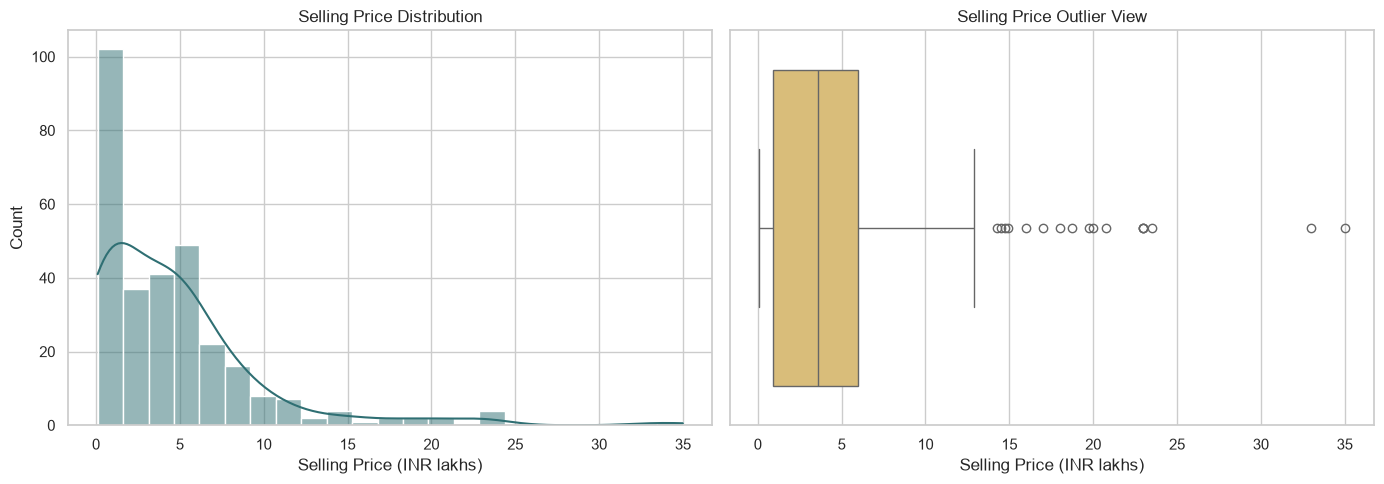

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data[TARGET_COLUMN], kde=True, ax=axes[0], color="#2f6f73")
axes[0].set_title("Selling Price Distribution")
axes[0].set_xlabel("Selling Price (INR lakhs)")

sns.boxplot(x=data[TARGET_COLUMN], ax=axes[1], color="#e9c46a")
axes[1].set_title("Selling Price Outlier View")
axes[1].set_xlabel("Selling Price (INR lakhs)")
plt.tight_layout()
plt.show()

**Business insight:** Used car prices are usually right-skewed because most inventory sits in affordable segments while a smaller number of premium vehicles carry much higher prices. This supports evaluating robust models and monitoring absolute errors by price segment.

## Numerical Feature Distributions

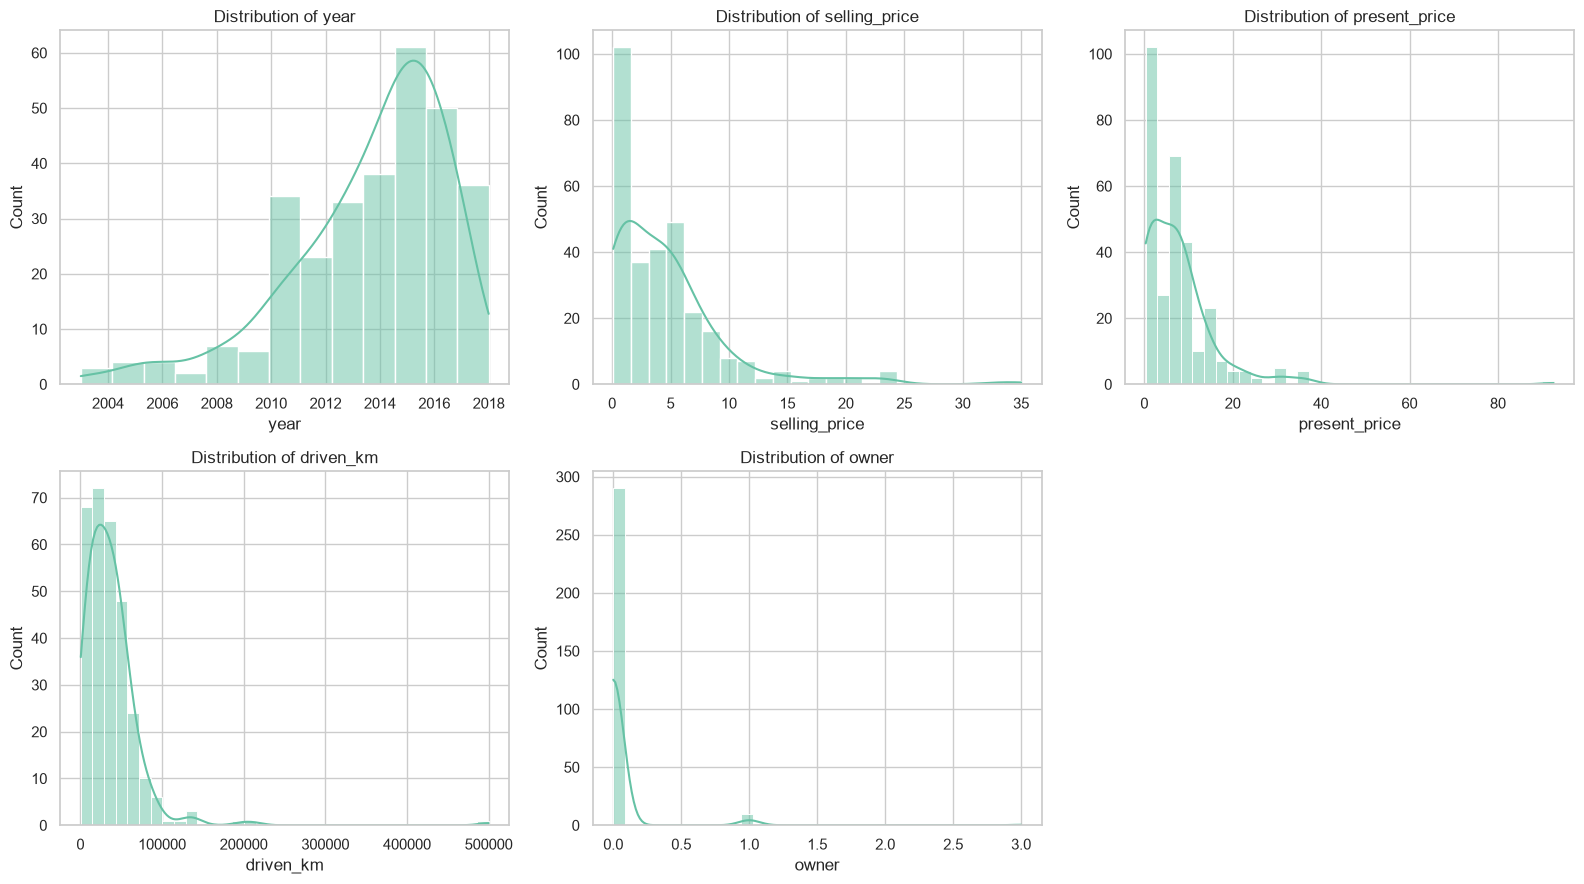

In [6]:
numeric_columns = data.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for index, column in enumerate(numeric_columns):
    sns.histplot(data[column], kde=True, ax=axes[index])
    axes[index].set_title(f"Distribution of {column}")

for axis in axes[len(numeric_columns):]:
    axis.set_visible(False)

plt.tight_layout()
plt.show()

**Business insight:** Present price and kilometers are expected to be strong pricing signals. Skewed kilometer and price distributions indicate that transformations and outlier treatment should be considered before model training.

## Categorical Analysis

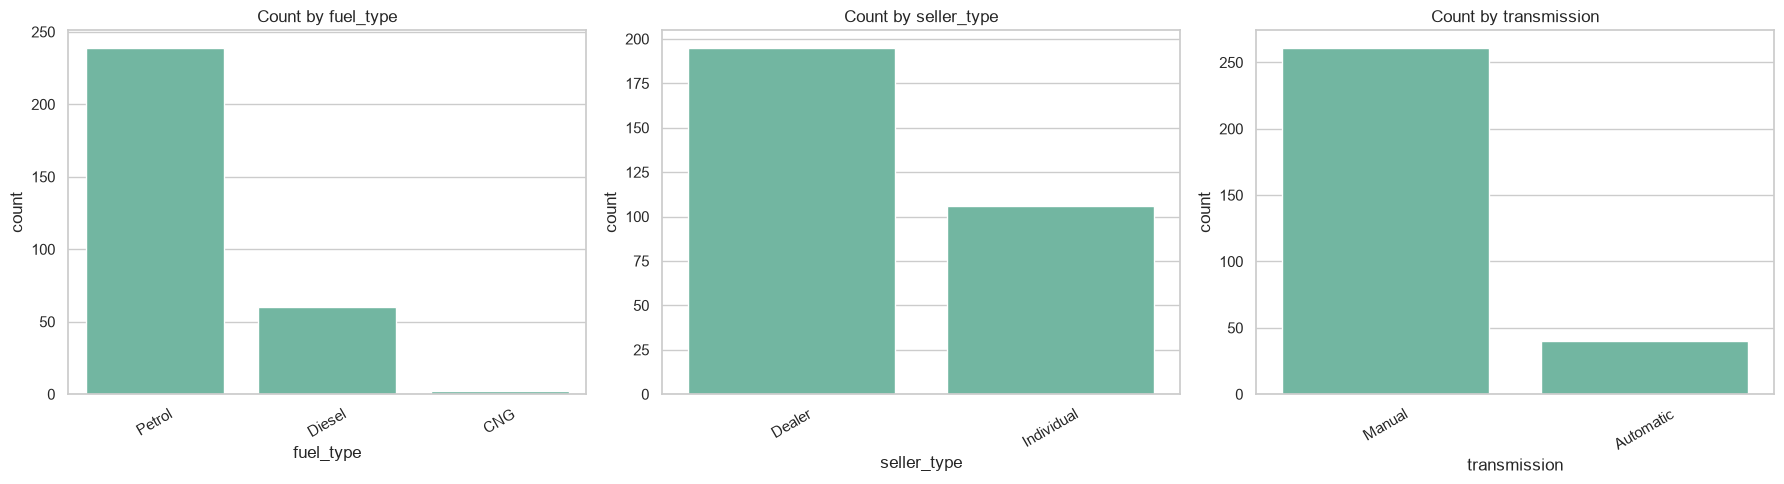

In [7]:
categorical_columns = [
    column for column in data.select_dtypes(include=["object", "category"]).columns
    if column != "car_name"
]

fig, axes = plt.subplots(1, len(categorical_columns), figsize=(6 * len(categorical_columns), 5))
if len(categorical_columns) == 1:
    axes = [axes]

for axis, column in zip(axes, categorical_columns):
    sns.countplot(data=data, x=column, ax=axis)
    axis.set_title(f"Count by {column}")
    axis.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Business insight:** Category imbalance matters because rare categories can produce unstable estimates. One-hot encoding with unknown-category handling is appropriate for deployment because new listing categories may appear after training.

## Selling Price by Category

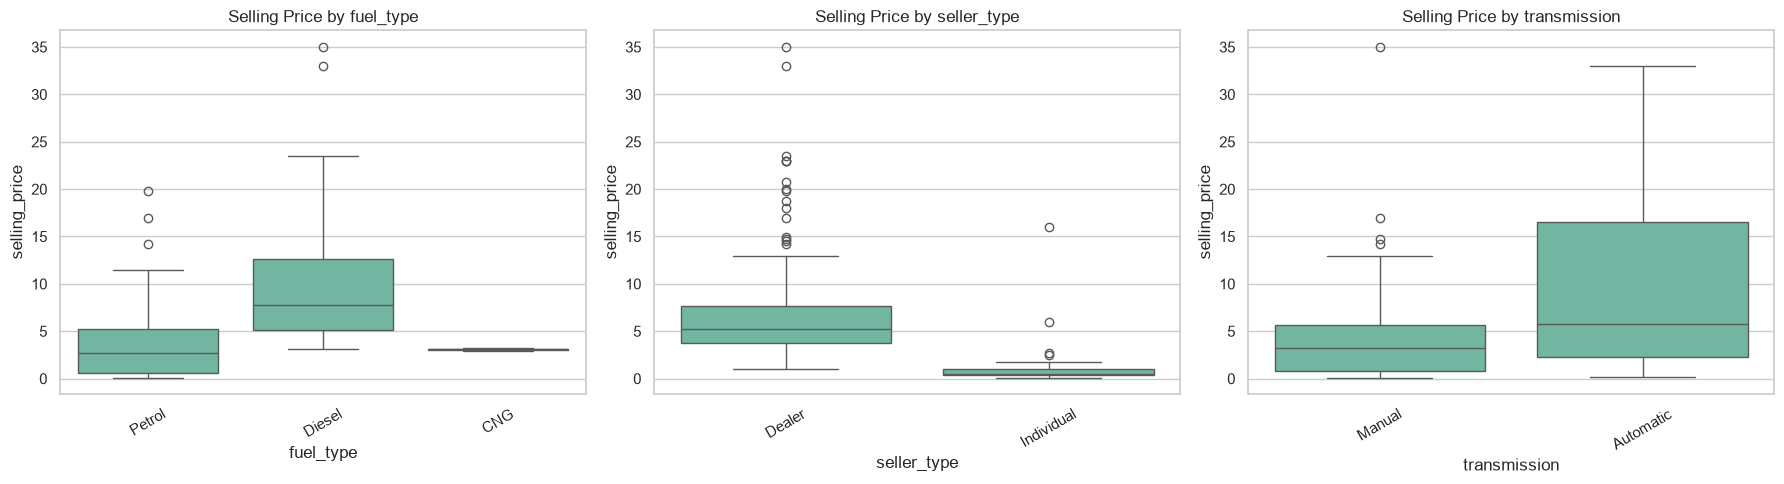

In [8]:
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(6 * len(categorical_columns), 5))
if len(categorical_columns) == 1:
    axes = [axes]

for axis, column in zip(axes, categorical_columns):
    sns.boxplot(data=data, x=column, y=TARGET_COLUMN, ax=axis)
    axis.set_title(f"Selling Price by {column}")
    axis.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Business insight:** Fuel type, transmission, and seller channel often reflect both vehicle quality and buyer preference. A systematic price difference across categories suggests these fields should remain explicit model inputs.

## Correlation Heatmap

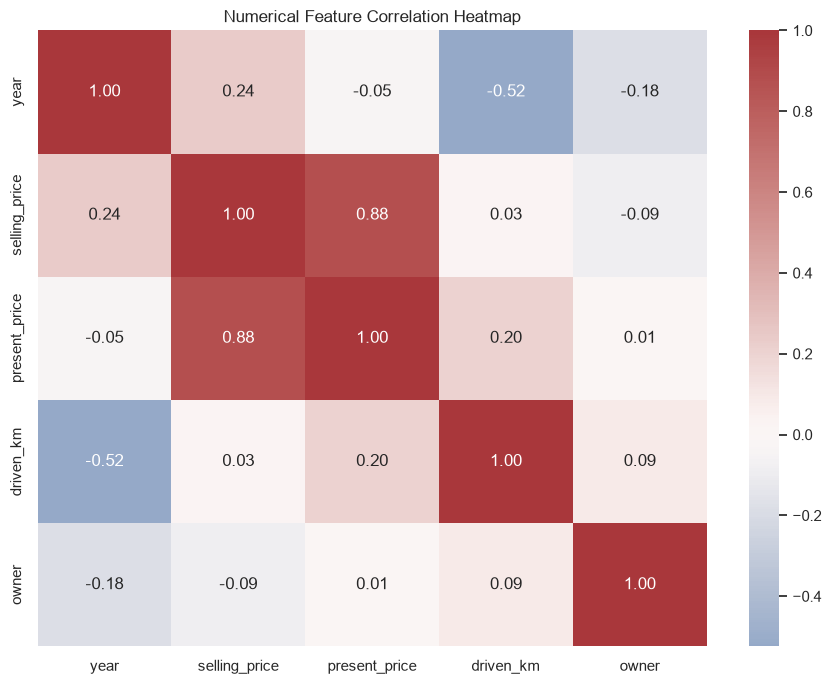

In [9]:
correlation = data[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

**Business insight:** Present price typically has the strongest relationship with resale price because it proxies vehicle segment and original value. Year and kilometers capture depreciation and usage, which should be made more explicit in feature engineering.

## Pair Plot

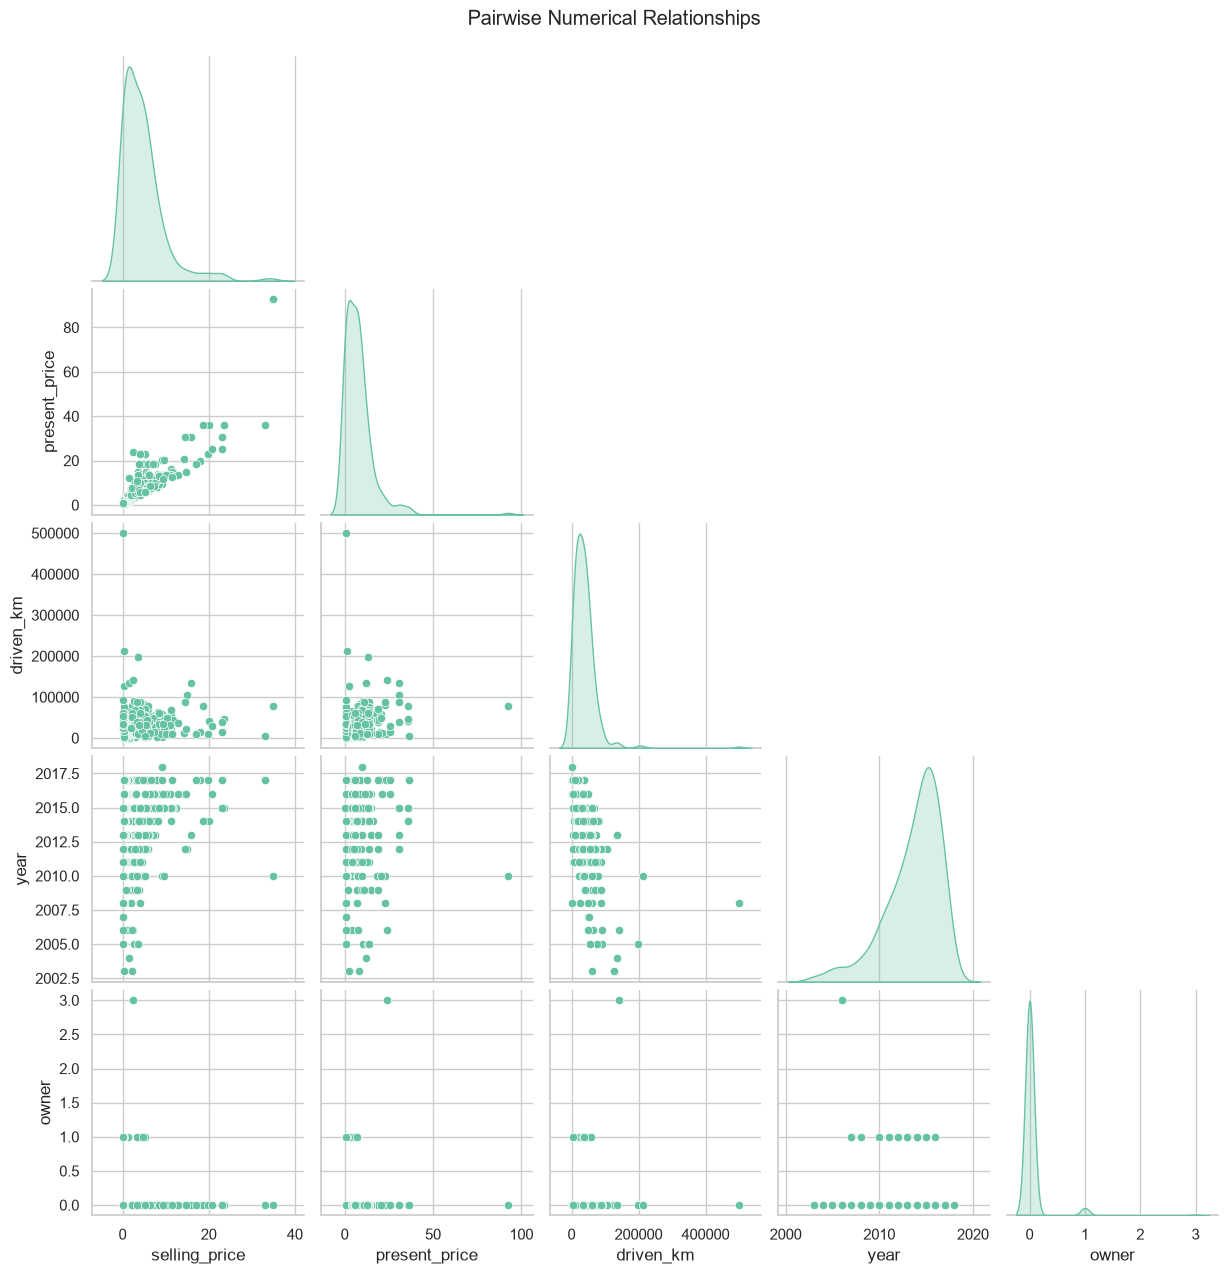

In [10]:
pairplot_columns = ["selling_price", "present_price", "driven_km", "year", "owner"]
sns.pairplot(data[pairplot_columns], diag_kind="kde", corner=True)
plt.suptitle("Pairwise Numerical Relationships", y=1.02)
plt.show()

**Business insight:** Pairwise relationships help identify nonlinearity and interaction effects. For example, present price may interact with age and kilometers differently across low-cost and premium vehicles.

## Outlier Detection

In [11]:
outlier_rows = []
for column in ["selling_price", "present_price", "driven_km"]:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((data[column] < lower) | (data[column] > upper)).sum()
    outlier_rows.append({"feature": column, "lower": lower, "upper": upper, "outliers": outlier_count})

display(pd.DataFrame(outlier_rows))

,feature,lower,upper,outliers
0,selling_price,-6.75,13.65,17
1,present_price,-11.85,22.95,14
2,driven_km,-35650.50,99417.50,8


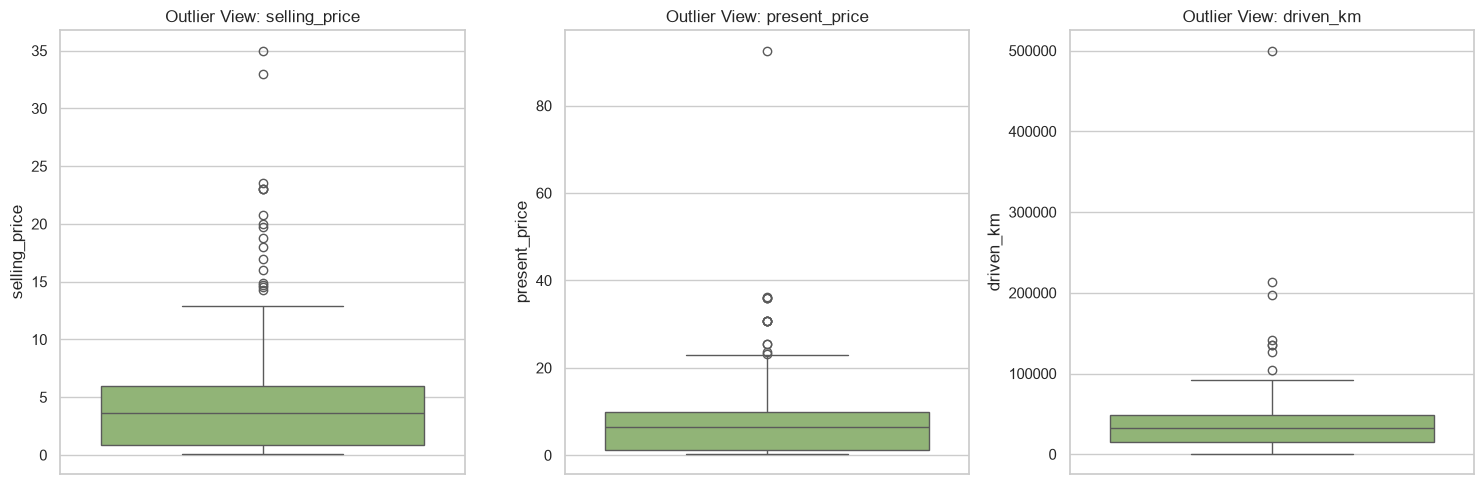

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, column in zip(axes, ["selling_price", "present_price", "driven_km"]):
    sns.boxplot(y=data[column], ax=axis, color="#90be6d")
    axis.set_title(f"Outlier View: {column}")

plt.tight_layout()
plt.show()

**Business insight:** Outliers may represent legitimate premium inventory or abnormal records. The preprocessing pipeline caps extreme numerical values rather than deleting them, preserving rare but useful market examples while reducing undue model influence.

## Engineered Feature Preview

In [13]:
cleaned_data = clean_data(data)
featured_data = engineer_features(cleaned_data)
display(featured_data.head())
display(featured_data[["car_age", "km_per_year", "depreciation", "depreciation_rate", "vehicle_age_bucket", "price_segment"]].describe(include="all"))

,car_name,year,selling_price,present_price,driven_km,fuel_type,seller_type,transmission,owner,car_age,km_per_year,brand,is_luxury_brand,vehicle_age_bucket,price_segment,log_present_price,log_driven_km,log_selling_price,depreciation,depreciation_rate
0,Ritz,2014,3.35,5.59,27000.0,Petrol,Dealer,Manual,0,12,2250.000000,ritz,0,9-12 years,mid_market,1.885553,10.203629,1.470176,2.24,0.400716
1,Sx4,2013,4.75,9.54,43000.0,Diesel,Dealer,Manual,0,13,3307.692308,sx4,0,12+ years,premium,2.355178,10.668979,1.749200,4.79,0.502096
2,Ciaz,2017,7.25,9.85,6900.0,Petrol,Dealer,Manual,0,9,766.666667,ciaz,0,9-12 years,premium,2.384165,8.839422,2.110213,2.60,0.263959
3,Wagon R,2011,2.85,4.15,5200.0,Petrol,Dealer,Manual,0,15,346.666667,wagon,0,12+ years,mid_market,1.638997,8.556606,1.348073,1.30,0.313253
4,Swift,2014,4.60,6.87,42450.0,Diesel,Dealer,Manual,0,12,3537.500000,swift,0,9-12 years,mid_market,2.063058,10.656106,1.722767,2.27,0.330422


,car_age,km_per_year,depreciation,depreciation_rate,vehicle_age_bucket,price_segment
count,299.000000,299.000000,299.000000,299.000000,299,299
unique,NaN,NaN,NaN,NaN,3,4
top,NaN,NaN,NaN,NaN,9-12 years,budget
freq,NaN,NaN,NaN,NaN,182,109
mean,12.384615,2644.941102,2.771070,0.370068,NaN,NaN
std,2.896868,1570.078609,3.398028,0.198006,NaN,NaN
min,8.000000,50.000000,0.030000,0.015748,NaN,NaN
25%,10.000000,1375.000000,0.398500,0.226949,NaN,NaN
50%,12.000000,2538.461538,1.650000,0.361493,NaN,NaN
75%,14.000000,3679.561688,3.510000,0.487538,NaN,NaN


**Business insight:** Engineered features translate raw listing data into marketplace concepts: age, usage intensity, depreciation, and price segment. These features are easier to explain to business stakeholders and often improve model performance.

## Final EDA Takeaways

- Present price, vehicle year, and driven kilometers are expected to be the dominant resale-price drivers.
- Category fields such as fuel type, seller type, and transmission show pricing differences and should be encoded through the pipeline.
- Outlier treatment is necessary because premium cars and high-kilometer cars can distort loss-sensitive models.
- Feature engineering should focus on depreciation, vehicle age, usage intensity, and price segmentation.
- Production inference must handle unseen categories, missing values, and valid user ranges consistently.